In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import os
import glob
import pyblock
import scipy.stats

# matplotlib settings
# --- Publication style settings ---
plt.rcParams.update({
    # Font
    "font.family": "Times New Roman",
    "font.serif": ["Arial"],  # or other preferred serif font
    "mathtext.fontset": "cm",            # Computer Modern for math text
    "text.usetex": False,                 # Use LaTeX for text rendering]
    "pdf.fonttype": 42,                 # Use LaTeX for text rendering

    # Figure
    "figure.figsize": (6, 4),            # width, height in inches
    "figure.dpi": 100,                   # high resolution

    # Axes
    "axes.titlesize": 14,
    "axes.labelsize": 12,
    "axes.linewidth": 1.2,
    "axes.grid": True,                   # optional, remove if you want no grid
    "grid.linestyle": "--",
    "grid.alpha": 0.7,

    # Ticks
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.top": True,
    "ytick.right": True,

    # Lines
    "lines.linewidth": 2,
    "lines.markersize": 6,

    # Legend
    "legend.fontsize": 10,
    "legend.frameon": False
})

aa3_to_aa1 = {
    "Ala": "A",
    "Arg": "R",
    "Asn": "N",
    "Asp": "D",
    "Cys": "C",
    "Gln": "Q",
    "Glu": "E",
    "Gly": "G",
    "His": "H",
    "Ile": "I",
    "Leu": "L",
    "Lys": "K",
    "Met": "M",
    "Phe": "F",
    "Pro": "P",
    "Ser": "S",
    "Thr": "T",
    "Trp": "W",
    "Tyr": "Y",
    "Val": "V",
    "Pro_cis": "Pc"
}

def RMSE(pred, true):
    return np.sqrt(np.mean((pred - true) ** 2))


tripeptides = ['Ala','Arg','Asn','Asp','Cys','Gln','Glu','Gly','His','Ile','Leu','Lys','Met','Phe','Ser','Thr','Trp','Tyr','Val']


In [6]:

base_path = "../AXA_peptides/"

rho_cutoff = 0.5

df = pd.DataFrame()
df['AA'] = tripeptides

pop_open_M12 = []
pop_open_M12_err = []
rg = []
rg_err = []
code = []

for aa in tripeptides:
    code.append(aa3_to_aa1[aa])
    filepath_M10 = os.path.join(base_path, aa, "SIM", "M10", "fopen.npy")
    filepath_rho = os.path.join(base_path, aa, "SIM", "rho_front_noexcl", "rho_front_frames.npy")
    filepath_rg = os.path.join(base_path, aa, "SIM", "BB_rg_data", "rg_traj_fit.txt")

    if not os.path.isfile(filepath_M10):
        print(f"Skipping {aa}: M10 file not found.")
        continue

    fopenM10 = np.load(filepath_M10)[:,1] # only middle residue
    rho = np.load(filepath_rho)[:,1] # only middle residue
    rho_open = (rho < rho_cutoff) * 1
    O = fopenM10 * rho_open
    rg_data = np.loadtxt(filepath_rg) 

    pop_open_M12.append(np.mean(O))
    rg.append(np.mean(rg_data))

    # errors M11
    reblock_data = pyblock.blocking.reblock(O)
    opt = pyblock.blocking.find_optimal_block(len(O), reblock_data)[0]
    err_fopen_M11 = reblock_data[opt][4]

    # errors rg
    reblock_data = pyblock.blocking.reblock(rg_data)
    opt = pyblock.blocking.find_optimal_block(len(rg_data), reblock_data)[0]
    err_rg = reblock_data[opt][4]

    # append errors
    pop_open_M12_err.append(err_fopen_M11)
    rg_err.append(err_rg)
       

df['p_open_M12'] = np.round(pop_open_M12, 4)
df['p_open_M12 ±'] = np.round(pop_open_M12_err, 4)
df['rg'] = np.round(rg, 4)
df['rg ±'] = np.round(rg_err, 4)
df['aa'] = code

# peptide correction factor - error-weighted average so that most final PFs are between 0.95-1.05

peptide_correction_factor = np.average(df['p_open_M12'], weights=1/df['p_open_M12 ±']**2)
print(peptide_correction_factor)

# calculate protection factors
df["PF_M12"] = np.round(1 / df['p_open_M12'], 4)
df["PF_M12 ±"] = np.round(df['p_open_M12 ±'] / (df['p_open_M12'] ** 2), 4)
df["PF_M12_corr"] = np.round(peptide_correction_factor / df['p_open_M12'], 4)
df["PF_M12_corr ±"] = np.round(df['p_open_M12 ±'] / (df['p_open_M12'] ** 2), 4)

# save
df.to_csv(f'AXA_tripeptides_M12_PF_rg.csv', index=False)








0.957089414992086


In [7]:
df

,AA,p_open_M12,p_open_M12 ±,rg,rg ±,aa,PF_M12,PF_M12 ±,PF_M12_corr,PF_M12_corr ±
0,Ala,0.9764,0.0013,0.3600,0.0011,A,1.0242,0.0014,0.9802,0.0014
1,Arg,0.9575,0.0023,0.3588,0.0033,R,1.0444,0.0025,0.9996,0.0025
2,Asn,0.9361,0.0033,0.3567,0.0012,N,1.0683,0.0038,1.0224,0.0038
3,Asp,0.8826,0.0076,0.3465,0.0026,D,1.1330,0.0098,1.0844,0.0098
4,Cys,0.9368,0.0031,0.3583,0.0012,C,1.0675,0.0035,1.0217,0.0035
5,Gln,0.9366,0.0048,0.3604,0.0018,Q,1.0677,0.0055,1.0219,0.0055
6,Glu,0.9512,0.0029,0.3555,0.0019,E,1.0513,0.0032,1.0062,0.0032
7,Gly,0.9653,0.0014,0.3495,0.0008,G,1.0359,0.0015,0.9915,0.0015
8,His,0.7987,0.0145,0.3487,0.0022,H,1.2520,0.0227,1.1983,0.0227
9,Ile,0.9043,0.0070,0.3592,0.0016,I,1.1058,0.0086,1.0584,0.0086


findfont: Font family ['Times New Roman'] not found. Falling back to DejaVu Sans.


findfont: Font family ['Times New Roman'] not found. Falling back to DejaVu Sans.
findfont: Font family ['Times New Roman'] not found. Falling back to DejaVu Sans.


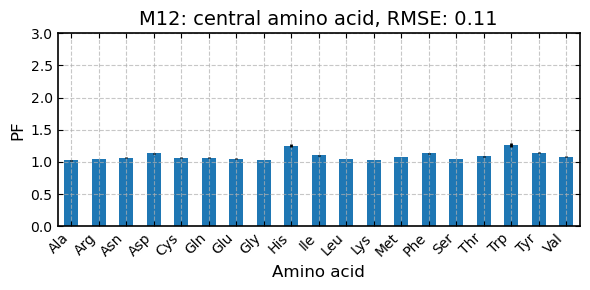

In [8]:
# plot PFs M11 and add RMSE to title

df.plot(x='AA', y='PF_M12', yerr='PF_M12 ±', kind='bar', figsize=(6, 3), legend=False)
plt.xlabel('Amino acid')
plt.ylabel('PF')
plt.xticks(rotation=45, ha='right')  
plt.title('M12: central amino acid, RMSE: {:.2f}'.format(np.round(RMSE(df['PF_M12'], np.ones(len(df))), 4)))
plt.ylim(0,3)
plt.tight_layout()
plt.savefig('PF_M12.png')

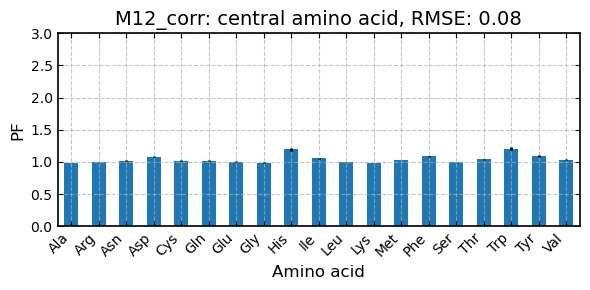

In [9]:
# plot PFs M10 and add RMSE to title

df.plot(x='AA', y='PF_M12_corr', yerr='PF_M12_corr ±', kind='bar', figsize=(6, 3), legend=False)
plt.xlabel('Amino acid')
plt.ylabel('PF')
plt.xticks(rotation=45, ha='right')  
plt.title('M12_corr: central amino acid, RMSE: {:.2f}'.format(np.round(RMSE(df['PF_M12_corr'], np.ones(len(df))), 4)))
plt.ylim(0,3)
plt.tight_layout()
plt.savefig('PF_M12_corr.png')

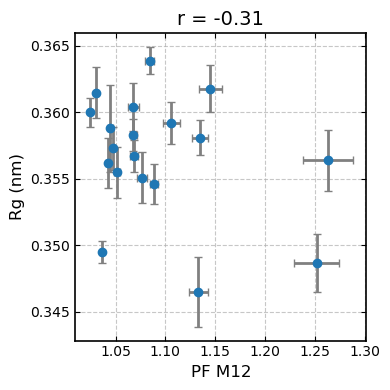

In [10]:
# correlation between PF M12 and rg

plt.figure(figsize=(4, 4))
plt.errorbar(x=df['PF_M12'], y=df['rg'], xerr=df['PF_M12 ±'], yerr=df['rg ±'], fmt='o', ecolor='gray', capsize=3)
plt.xlabel('PF M12')
plt.ylabel('Rg (nm)')
plt.title('r = {:.2f}'.format(scipy.stats.pearsonr(df['PF_M12'], df['rg'])[0]))
plt.tight_layout()
plt.savefig('PF_M12_rg_correlation.png')


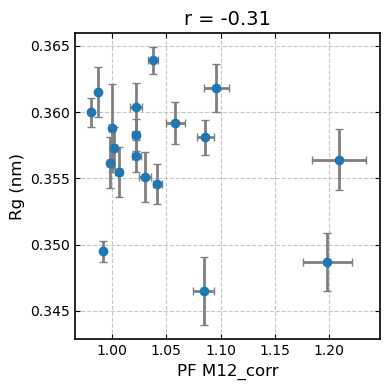

In [11]:
# correlation between PF M12 and rg

plt.figure(figsize=(4, 4))
plt.errorbar(x=df['PF_M12_corr'], y=df['rg'], xerr=df['PF_M12_corr ±'], yerr=df['rg ±'], fmt='o', ecolor='gray', capsize=3)
plt.xlabel('PF M12_corr')
plt.ylabel('Rg (nm)')
plt.title('r = {:.2f}'.format(scipy.stats.pearsonr(df['PF_M12_corr'], df['rg'])[0]))
plt.tight_layout()
plt.savefig('PF_M12_corr_rg_correlation.png')


In [12]:
print(peptide_correction_factor)

0.957089414992086


In [14]:
np.mean(df['p_open_M12'])

0.918221052631579

In [15]:
np.average(df['p_open_M12'], weights=1/df['p_open_M12 ±']**2)

0.957089414992086

In [16]:
df

,AA,p_open_M12,p_open_M12 ±,rg,rg ±,aa,PF_M12,PF_M12 ±,PF_M12_corr,PF_M12_corr ±
0,Ala,0.9764,0.0013,0.3600,0.0011,A,1.0242,0.0014,0.9802,0.0014
1,Arg,0.9575,0.0023,0.3588,0.0033,R,1.0444,0.0025,0.9996,0.0025
2,Asn,0.9361,0.0033,0.3567,0.0012,N,1.0683,0.0038,1.0224,0.0038
3,Asp,0.8826,0.0076,0.3465,0.0026,D,1.1330,0.0098,1.0844,0.0098
4,Cys,0.9368,0.0031,0.3583,0.0012,C,1.0675,0.0035,1.0217,0.0035
5,Gln,0.9366,0.0048,0.3604,0.0018,Q,1.0677,0.0055,1.0219,0.0055
6,Glu,0.9512,0.0029,0.3555,0.0019,E,1.0513,0.0032,1.0062,0.0032
7,Gly,0.9653,0.0014,0.3495,0.0008,G,1.0359,0.0015,0.9915,0.0015
8,His,0.7987,0.0145,0.3487,0.0022,H,1.2520,0.0227,1.1983,0.0227
9,Ile,0.9043,0.0070,0.3592,0.0016,I,1.1058,0.0086,1.0584,0.0086
